In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/bm/v93fcqrd7kq6vwyfqyx20p5w0000gn/T/ipykernel_11653/3737875437.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

72 possible layouts


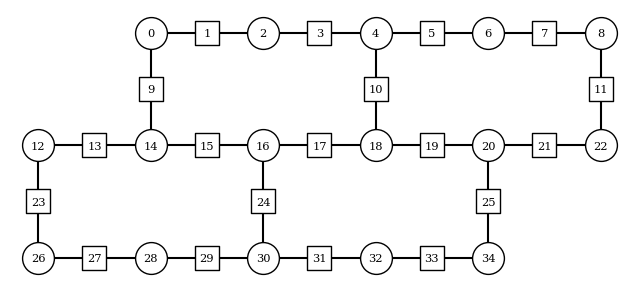

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

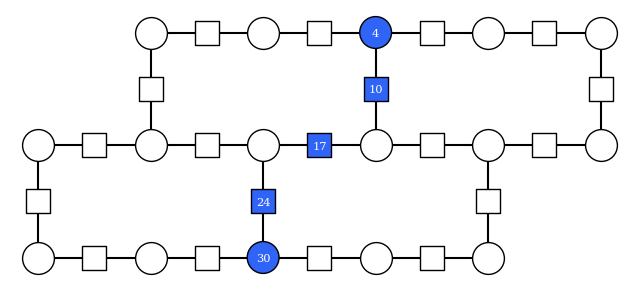

In [ ]:
from z2hex.gdd import random, constant, counteract_rotation, zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)

# m, g, lamb
parameters = [(5, 5, 1), (5, 0.01, 1), (5, 0, 1), (1.5, 5, 1), (1.5, 2, 1), (1.5, 0.01, 1), (1.5, 0, 1), (0, 0, 1), (0, 2, 1), (0, 5, 1)]

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
string = [4, 10, 17, 24, 30]
# string = [4, 10, 18, 17, 16, 24, 30, 15, 14, 19, 20]

final_time = 5.25
dt = 0.175
steps = 32
desired_error = 1e-2

pt_num_randomizations = 5000
pt_shots_per_randomization = 100

shots = pt_num_randomizations * pt_shots_per_randomization
max_shots = 10000000

confidence = 0.9

cal = True
postselect_odr = True
flip_threshold = 2
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

# if callable(g_func):
#     g_func.__name__ = from_matrix.__name__

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": pt_num_randomizations,
        "shots_per_randomization": pt_shots_per_randomization
    }
}

# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string))

# Record tools

## Add separator

In [5]:
# execrecord.add_separator()

# Circuit generation & observables

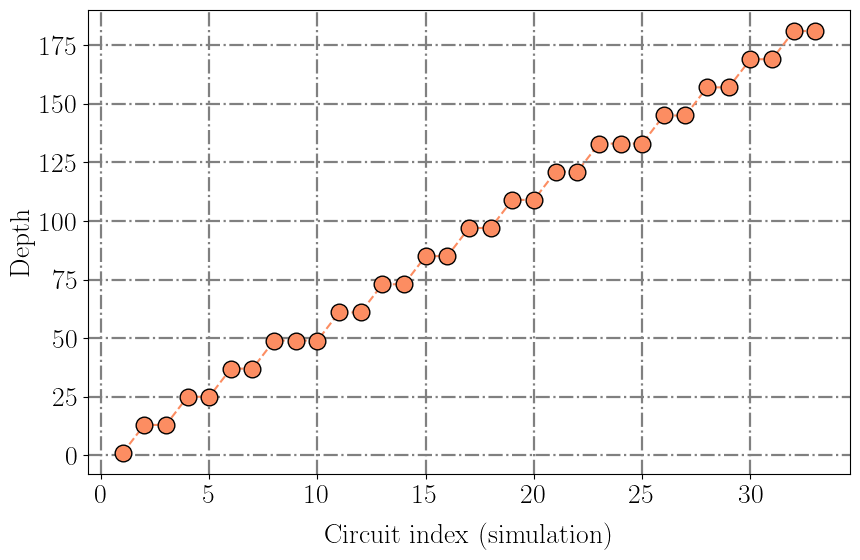

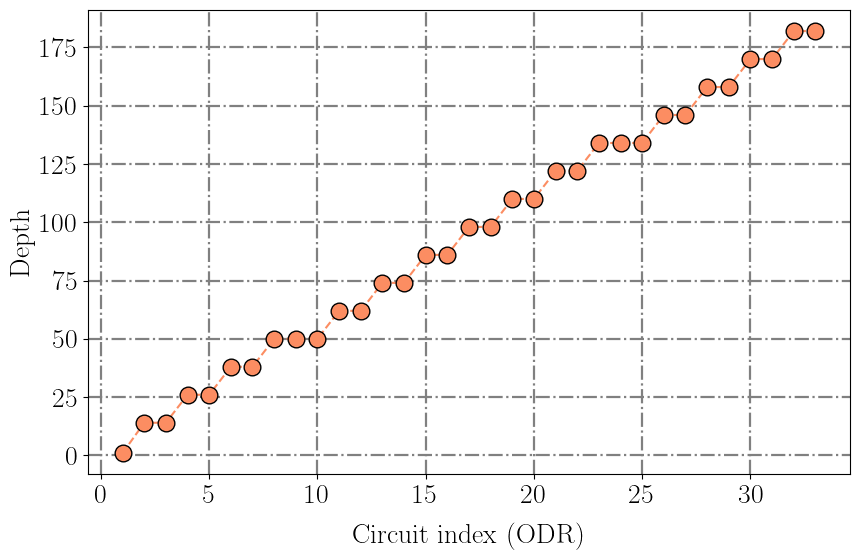

In [6]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, simulation_and_odr_circuits_2t, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
import numpy as np

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

circuits = []
cal_circuits = []
extra_options = []

for i, (m, g, lamb) in enumerate(parameters):
    if all_or_first_layout_qubit == True:
        all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
        layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
    elif isinstance(all_or_first_layout_qubit, int):
        layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
    else:
        layouts = None
    circs_args = (lattice, m, g, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, False)
    this_extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(m).tolist(), "h": np.array(g).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis, "max_shots": max_shots} | ({"fractional_gates": True} if fractional_gates else {})
    extra_options.append(this_extra_options)
    if cal:
        this_circuits, this_cal_circuits = simulation_and_odr_circuits(*circs_args)
        # this_circuits, this_cal_circuits = simulation_and_odr_circuits_2t(*circs_args)
        circuits.append(this_circuits)
        cal_circuits.append(this_cal_circuits)
    else:
        this_circuits = string_quench_simulation_circuits_dt(*circs_args)
        circuits.append(this_circuits)

observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0][0], x_label="Circuit index (simulation)")
plot_circuit_arr_depth(cal_circuits[0][0], x_label="Circuit index (ODR)")

In [7]:
# from utils.circs import save_circs

# save_circs("trotter_chain_circs_L_5.qpy", circuits)
# save_circs("trotter_chain_odr_circs_L_5.qpy", odr_circuits)

# Send jobs to hardware

In [8]:
from utils.postselection_multithreaded import execute_postselected_sampler_batch

for i, (m, g, lamb) in enumerate(parameters):
    print(f"\rSending m = {m}, g = {g}, λ = {lamb} batch", end="")
    if cal:
        jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i], observable_generating_funcs, postselects_generating_func=postselection_operators_func, cal_circuits=cal_circuits[i], extra_options=extra_options[i], job_db=job_db, diagonal_basis="Z", max_shots=max_shots)
    else:
        jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i], observable_generating_funcs, postselects_generating_func=postselection_operators_func, extra_options=extra_options[i], job_db=job_db, diagonal_basis="Z", max_shots=max_shots)
    execrecord.add_record(m, g, lamb, g_func.__name__ if callable(g_func) else None, final_time, dt, steps, lattice, all_or_first_layout_qubit, device, shots, string, x_basis, cal)

Sending m = 5, g = 5, λ = 1 batch

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:848: UserWarning: The backend ibm_aachen currently has a status of internal.
  warnings.warn(


Sending m = 5, g = 0.01, λ = 1 batch

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:848: UserWarning: The backend ibm_aachen currently has a status of internal.
  warnings.warn(


Sending m = 0, g = 5, λ = 1 batchchtch